# 4 - Diffusion Posterior Sampling (DPS)

The previous methods learn from the noisy image itself. **DPS** instead uses a **pretrained diffusion model** as a strong prior on what faces look like, and runs the reverse diffusion *guided* toward our noisy measurement.

We sample from the posterior `p(x | y)` by alternating, at every denoising step:
1. a normal diffusion step from the unconditional face model, and
2. a gradient step that pulls the estimate toward the data `y` via the likelihood `||y - x0_hat||^2` (Chung et al., 2022).

For Gaussian *denoising* the forward operator is the identity (`y = x + noise`), which makes the likelihood term especially simple.

We start from a **CelebA-HQ face** corrupted with **additive white Gaussian noise** (sigma = 25/255). Every notebook in this tutorial uses the exact same image and noise, so the PSNR numbers are directly comparable across methods.

### Setup
We import a face diffusion model straight from the HuggingFace Hub (`google/ddpm-celebahq-256`, trained on CelebA-HQ). Only `diffusers` is needed beyond Colab's defaults.

In [1]:
!pip install -q diffusers scikit-image

### Load the CelebA face and add Gaussian noise

clean (256, 256, 3),  noise sigma = 0.098 (25/255)
noisy PSNR = 20.60 dB


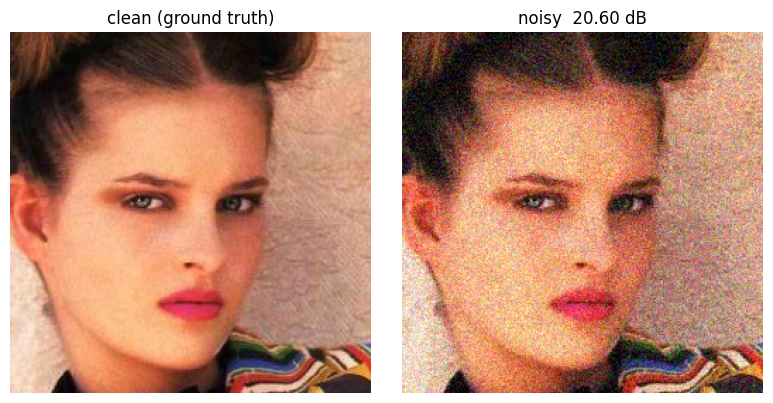

In [2]:
import io, requests, numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Reproducibility
SEED  = 0
SIGMA = 25 / 255.0          # Gaussian noise std, on the [0, 1] intensity scale
IMG   = 256                 # all notebooks use 256x256 (matches the DDPM model)

def get_celeba_face(size=IMG, index=3):
    """Fetch a single CelebA-HQ face (256x256) via the HuggingFace datasets
    server. Falls back to a bundled skimage portrait if the download fails so
    the notebook always runs offline."""
    try:
        api = ("https://datasets-server.huggingface.co/first-rows?"
               "dataset=korexyz/celeba-hq-256x256&config=default&split=train")
        rows = requests.get(api, timeout=30).json()["rows"]
        src  = rows[index]["row"]["image"]["src"]
        img  = Image.open(io.BytesIO(requests.get(src, timeout=30).content))
    except Exception as e:
        print(f"[warn] CelebA download failed ({e}); using skimage sample face.")
        from skimage.data import astronaut
        img = Image.fromarray(astronaut())
    return img.convert("RGB").resize((size, size), Image.LANCZOS)

def psnr(a, b):
    """Peak signal-to-noise ratio for images in [0, 1]."""
    mse = np.mean((a.astype(np.float64) - b.astype(np.float64)) ** 2)
    return 100.0 if mse == 0 else 20 * np.log10(1.0 / np.sqrt(mse))

# Ground truth + noisy measurement -----------------------------------------
rng   = np.random.default_rng(SEED)
clean = np.asarray(get_celeba_face(), np.float32) / 255.0            # (H,W,3) in [0,1]
noisy = np.clip(clean + rng.normal(0, SIGMA, clean.shape), 0, 1).astype(np.float32)

print(f"clean {clean.shape},  noise sigma = {SIGMA:.3f} ({SIGMA*255:.0f}/255)")
print(f"noisy PSNR = {psnr(clean, noisy):.2f} dB")

def show(images, titles, suptitle=None):
    n = len(images)
    plt.figure(figsize=(4 * n, 4))
    for k, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(1, n, k + 1)
        plt.imshow(np.clip(im, 0, 1)); plt.title(t); plt.axis("off")
    if suptitle: plt.suptitle(suptitle)
    plt.tight_layout(); plt.show()

show([clean, noisy], ["clean (ground truth)", f"noisy  {psnr(clean, noisy):.2f} dB"])

### Load the pretrained CelebA diffusion model

In [3]:
import torch
from diffusers import UNet2DModel, DDPMScheduler
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

model = UNet2DModel.from_pretrained('google/ddpm-celebahq-256').to(device).eval()
sched = DDPMScheduler.from_pretrained('google/ddpm-celebahq-256')
print(f'{sum(p.numel() for p in model.parameters())/1e6:.0f}M params, '
      f'native size {model.config.sample_size}')

/home/shij3/.conda/envs/denoising/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cannot initialize model with low cpu memory usage because `accelerate` was not found in the environment. Defaulting to `low_cpu_mem_usage=False`. It is strongly recommended to install `accelerate` for faster and less memory-intense model loading. You can do so with: 
```
pip install accelerate
```
.


device: cuda


/home/shij3/.conda/envs/denoising/lib/python3.10/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


An error occurred while trying to fetch google/ddpm-celebahq-256: google/ddpm-celebahq-256 does not appear to have a file named diffusion_pytorch_model.safetensors.


Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


114M params, native size 256


### DPS sampling loop
At each timestep `t` we (1) predict the noise, (2) form the clean estimate `x0_hat` (Tweedie's formula), (3) take the scheduler's reverse step, and (4) nudge the result down the gradient of the data-fidelity term. The model works in `[-1, 1]`, so we map the measurement `y` accordingly.

On a Colab T4 this runs in roughly 2-3 minutes for 250 steps. Increase `NUM_STEPS` for slightly higher quality.

In [4]:
import time
torch.manual_seed(SEED)
NUM_STEPS = 250          # diffusion steps (fewer = faster, more = better)
ZETA      = 3.0          # data-fidelity guidance strength
sched.set_timesteps(NUM_STEPS)
abars = sched.alphas_cumprod.to(device)

# measurement in the model's [-1, 1] range
y = torch.from_numpy(noisy).permute(2, 0, 1)[None].to(device) * 2 - 1

x = torch.randn(1, 3, IMG, IMG, device=device)   # start from pure noise (x_T)
t0 = time.time()
for t in sched.timesteps:
    x = x.detach().requires_grad_(True)
    eps = model(x, t).sample                      # predicted noise
    ab  = abars[t]
    x0  = (x - (1 - ab).sqrt() * eps) / ab.sqrt() # Tweedie: clean estimate
    x_prev = sched.step(eps, t, x).prev_sample    # unconditional reverse step
    resid  = (y - x0.clamp(-1, 1))                # data fidelity (A = identity)
    grad   = torch.autograd.grad(resid.pow(2).sum().sqrt(), x)[0]
    x = (x_prev - ZETA * grad).detach()           # guide toward the measurement
print(f'DPS sampling done in {time.time()-t0:.1f}s')

den = ((x.clamp(-1, 1) + 1) / 2)[0].permute(1, 2, 0).cpu().numpy()
print(f'noisy {psnr(clean, noisy):.2f} dB  ->  DPS {psnr(clean, den):.2f} dB')

DPS sampling done in 12.7s
noisy 20.60 dB  ->  DPS 30.36 dB


### Results

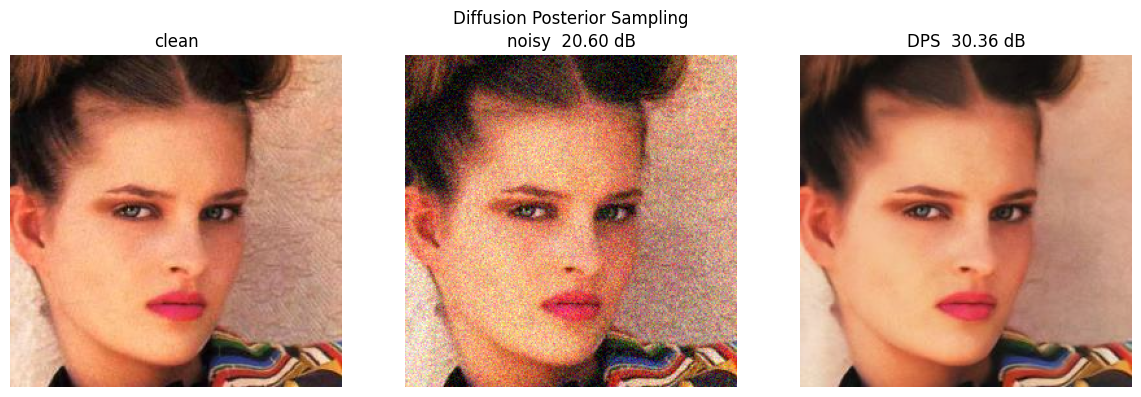

In [5]:
show([clean, noisy, den],
     ['clean', f'noisy  {psnr(clean, noisy):.2f} dB', f'DPS  {psnr(clean, den):.2f} dB'],
     suptitle='Diffusion Posterior Sampling')

### Takeaways
* DPS needs **no training and no noisy/clean pairs** -- it reuses a pretrained face prior, so it typically gives the sharpest, most realistic result here.
* The same loop solves other inverse problems (inpainting, super-resolution, deblurring) by swapping the forward operator `A` in the fidelity term `||y - A(x0_hat)||`.
* Trade-offs: it is the slowest method and its prior is domain-specific (faces) -- the generative model can 'hallucinate' plausible detail that was not in the measurement.